In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

In [5]:
df = pd.read_csv(r"C:\Users\HP\OneDrive\Desktop\dataset.csv")

print("Dataset loaded successfully")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully
Shape: (10000, 14)


,Customer_ID,Gender,Senior_Citizen,Tenure_Months,Contract_Type,Internet_Service,Payment_Method,Monthly_Charges_INR,Total_Charges_INR,Tech_Support,Online_Security,Support_Tickets_6M,Avg_Data_Usage_GB,Churn
0,TEL00001,Male,No,68,Month-to-month,DSL,Bank Transfer,619.60,"43,796.41",No,No,2.0,78.23,Churn
1,TEL00002,Male,No,64,Month-to-month,Fiber,Cash,"1,492.51","91,446.97",Yes,No,5.0,116.38,Churn
2,TEL00003,Female,Yes,12,Month-to-month,Fiber,Cash,974.56,"12,432.49",No,Yes,1.0,111.82,Not Churn
3,TEL00004,Male,Yes,51,Month-to-month,DSL,Cash,309.56,"16,076.23",No,No,5.0,60.43,Churn
4,TEL00005,Female,No,56,Month-to-month,Fiber,Cash,"1,410.78","77,003.95",No,Yes,5.0,118.55,Churn


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Customer_ID          10000 non-null  object 
 1   Gender               9965 non-null   object 
 2   Senior_Citizen       9572 non-null   object 
 3   Tenure_Months        9970 non-null   object 
 4   Contract_Type        9981 non-null   object 
 5   Internet_Service     9854 non-null   object 
 6   Payment_Method       9561 non-null   object 
 7   Monthly_Charges_INR  9528 non-null   object 
 8   Total_Charges_INR    9978 non-null   object 
 9   Tech_Support         9530 non-null   object 
 10  Online_Security      9968 non-null   object 
 11  Support_Tickets_6M   1175 non-null   float64
 12  Avg_Data_Usage_GB    1178 non-null   float64
 13  Churn                1200 non-null   object 
dtypes: float64(2), object(12)
memory usage: 1.1+ MB


In [7]:
print("Missing values:")
display(df.isnull().sum())

print("Duplicate records:", df.duplicated().sum())

Missing values:


Customer_ID               0
Gender                   35
Senior_Citizen          428
Tenure_Months            30
Contract_Type            19
Internet_Service        146
Payment_Method          439
Monthly_Charges_INR     472
Total_Charges_INR        22
Tech_Support            470
Online_Security          32
Support_Tickets_6M     8825
Avg_Data_Usage_GB      8822
Churn                  8800
dtype: int64

Duplicate records: 68


Churn
Not Churn    711
Churn        489
Name: count, dtype: int64


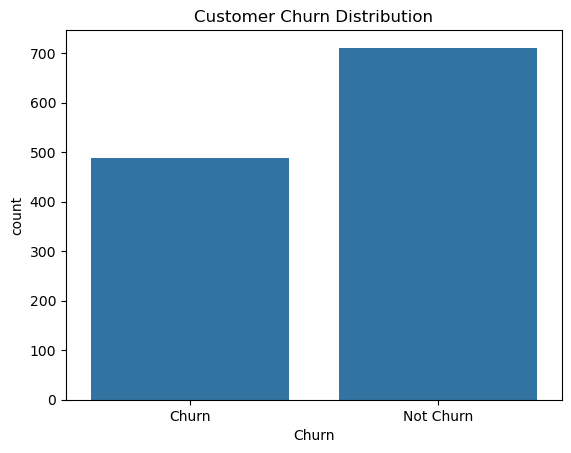

In [8]:
print(df["Churn"].value_counts())

sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

In [9]:
for col in df.columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).head(15))


Customer_ID
Customer_ID
2098    9
4854    9
1661    9
2016    8
1018    8
1684    8
2855    8
4719    8
2772    8
4747    8
2390    7
3156    7
1699    7
3300    7
4072    7
Name: count, dtype: int64

Gender
Gender
Male      590
Female    575
NaN        35
12415       7
10949       6
15153       6
10947       6
11561       6
12892       6
12939       6
13535       6
19745       5
18283       5
12486       5
17727       5
Name: count, dtype: int64

Senior_Citizen
Senior_Citizen
No       971
Rahul    873
Kiran    870
Ravi     860
Amit     850
Priya    835
Neha     825
Anuja    822
Pooja    821
Sneha    810
Arjun    806
NaN      428
Yes      229
Name: count, dtype: int64

Tenure_Months
Tenure_Months
Female    4308
Male      4135
Other      357
NaN         30
20          27
62          25
71          24
6           23
60          23
32          22
7           21
15          21
57          21
56          20
70          20
Name: count, dtype: int64

Contract_Type
Contract_Type
Furniture    

In [10]:
data = df.copy()

print("Original dataset shape:", data.shape)
print("Working dataset shape:", data.shape)

Original dataset shape: (10000, 14)
Working dataset shape: (10000, 14)


In [11]:
# Remove leading and trailing spaces from column names
data.columns = data.columns.str.strip()

# Replace empty strings and spaces with NaN
data.replace(r'^\s*$', np.nan, regex=True, inplace=True)

print("Missing values before cleaning:")
display(data.isnull().sum())

Missing values before cleaning:


Customer_ID               0
Gender                   35
Senior_Citizen          428
Tenure_Months            30
Contract_Type            19
Internet_Service        146
Payment_Method          439
Monthly_Charges_INR     472
Total_Charges_INR        22
Tech_Support            470
Online_Security          32
Support_Tickets_6M     8825
Avg_Data_Usage_GB      8822
Churn                  8800
dtype: int64

In [12]:
numeric_columns = [
    "Tenure_Months",
    "Monthly_Charges_INR",
    "Total_Charges_INR",
    "Support_Tickets_6M",
    "Avg_Data_Usage_GB"
]

for col in numeric_columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Invalid tenure values
data.loc[
    (data["Tenure_Months"] < 0) |
    (data["Tenure_Months"] > 72),
    "Tenure_Months"
] = np.nan

# Negative charges are invalid
data.loc[data["Monthly_Charges_INR"] < 0, "Monthly_Charges_INR"] = np.nan
data.loc[data["Total_Charges_INR"] < 0, "Total_Charges_INR"] = np.nan

# Negative support tickets and data usage are invalid
data.loc[data["Support_Tickets_6M"] < 0, "Support_Tickets_6M"] = np.nan
data.loc[data["Avg_Data_Usage_GB"] < 0, "Avg_Data_Usage_GB"] = np.nan

print("Invalid numeric values converted to missing values.")

Invalid numeric values converted to missing values.


In [13]:
# Numeric columns
for col in numeric_columns:
    data[col] = data[col].fillna(data[col].median())

# Categorical columns
categorical_columns = data.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for col in categorical_columns:
    if data[col].notna().any():
        data[col] = data[col].fillna(data[col].mode()[0])

print("Missing values after imputation:")
display(data.isnull().sum())

Missing values after imputation:


Customer_ID            0
Gender                 0
Senior_Citizen         0
Tenure_Months          0
Contract_Type          0
Internet_Service       0
Payment_Method         0
Monthly_Charges_INR    0
Total_Charges_INR      0
Tech_Support           0
Online_Security        0
Support_Tickets_6M     0
Avg_Data_Usage_GB      0
Churn                  0
dtype: int64

In [14]:
print("Duplicates before removal:", data.duplicated().sum())

data.drop_duplicates(inplace=True)

print("Duplicates after removal:", data.duplicated().sum())
print("Dataset shape after cleaning:", data.shape)

Duplicates before removal: 68
Duplicates after removal: 0
Dataset shape after cleaning: (9932, 14)


In [15]:
display(data.head())

print("Dataset information:")
data.info()

print("\nMissing values:", data.isnull().sum().sum())
print("Duplicate records:", data.duplicated().sum())

,Customer_ID,Gender,Senior_Citizen,Tenure_Months,Contract_Type,Internet_Service,Payment_Method,Monthly_Charges_INR,Total_Charges_INR,Tech_Support,Online_Security,Support_Tickets_6M,Avg_Data_Usage_GB,Churn
0,TEL00001,Male,No,68.0,Month-to-month,DSL,Bank Transfer,619.600,0.0,No,No,2.0,78.23,Churn
1,TEL00002,Male,No,64.0,Month-to-month,Fiber,Cash,700.865,0.0,Yes,No,5.0,116.38,Churn
2,TEL00003,Female,Yes,12.0,Month-to-month,Fiber,Cash,974.560,0.0,No,Yes,1.0,111.82,Not Churn
3,TEL00004,Male,Yes,51.0,Month-to-month,DSL,Cash,309.560,0.0,No,No,5.0,60.43,Churn
4,TEL00005,Female,No,56.0,Month-to-month,Fiber,Cash,700.865,0.0,No,Yes,5.0,118.55,Churn


Dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 9932 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Customer_ID          9932 non-null   object 
 1   Gender               9932 non-null   object 
 2   Senior_Citizen       9932 non-null   object 
 3   Tenure_Months        9932 non-null   float64
 4   Contract_Type        9932 non-null   object 
 5   Internet_Service     9932 non-null   object 
 6   Payment_Method       9932 non-null   object 
 7   Monthly_Charges_INR  9932 non-null   float64
 8   Total_Charges_INR    9932 non-null   float64
 9   Tech_Support         9932 non-null   object 
 10  Online_Security      9932 non-null   object 
 11  Support_Tickets_6M   9932 non-null   float64
 12  Avg_Data_Usage_GB    9932 non-null   float64
 13  Churn                9932 non-null   object 
dtypes: float64(5), object(9)
memory usage: 1.1+ MB

Missing values: 0
Duplic

In [ ]:
feature 

In [16]:
data["Tenure_Category"] = pd.cut(
    data["Tenure_Months"],
    bins=[-1, 12, 24, 48, 72],
    labels=["New", "Short-term", "Medium-term", "Long-term"]
)

display(data[["Tenure_Months", "Tenure_Category"]].head(10))

,Tenure_Months,Tenure_Category
0,68.0,Long-term
1,64.0,Long-term
2,12.0,New
3,51.0,Long-term
4,56.0,Long-term
5,33.0,Medium-term
6,30.0,Medium-term
7,23.0,Short-term
8,24.0,Short-term
9,39.0,Medium-term


In [17]:
data["Average_Monthly_Spending"] = np.where(
    data["Tenure_Months"] > 0,
    data["Total_Charges_INR"] / data["Tenure_Months"],
    data["Monthly_Charges_INR"]
)

display(data[[
    "Tenure_Months",
    "Total_Charges_INR",
    "Average_Monthly_Spending"
]].head(10))

,Tenure_Months,Total_Charges_INR,Average_Monthly_Spending
0,68.0,0.0,0.0
1,64.0,0.0,0.0
2,12.0,0.0,0.0
3,51.0,0.0,0.0
4,56.0,0.0,0.0
5,33.0,0.0,0.0
6,30.0,0.0,0.0
7,23.0,0.0,0.0
8,24.0,0.0,0.0
9,39.0,0.0,0.0


In [18]:
# Internet service indicator
data["Has_Internet_Service"] = (
    data["Internet_Service"].astype(str).str.strip().str.lower()
    .isin(["yes", "fiber optic", "dsl", "true", "1"])
).astype(int)

# Technical support indicator
data["Has_Tech_Support"] = (
    data["Tech_Support"].astype(str).str.strip().str.lower()
    .isin(["yes", "true", "1"])
).astype(int)

# Online security indicator
data["Has_Online_Security"] = (
    data["Online_Security"].astype(str).str.strip().str.lower()
    .isin(["yes", "true", "1"])
).astype(int)

display(data[[
    "Internet_Service",
    "Has_Internet_Service",
    "Tech_Support",
    "Has_Tech_Support",
    "Online_Security",
    "Has_Online_Security"
]].head(10))

,Internet_Service,Has_Internet_Service,Tech_Support,Has_Tech_Support,Online_Security,Has_Online_Security
0,DSL,1,No,0,No,0
1,Fiber,0,Yes,1,No,0
2,Fiber,0,No,0,Yes,1
3,DSL,1,No,0,No,0
4,Fiber,0,No,0,Yes,1
5,6,0,No,0,No,0
6,DSL,1,No,0,No,0
7,DSL,1,No,0,Yes,1
8,Fiber,0,No,0,No,0
9,Fiber,0,No,0,Yes,1


In [19]:
data["Ticket_Intensity"] = np.where(
    data["Tenure_Months"] > 0,
    data["Support_Tickets_6M"] / data["Tenure_Months"],
    data["Support_Tickets_6M"]
)

display(data[[
    "Support_Tickets_6M",
    "Tenure_Months",
    "Ticket_Intensity"
]].head(10))

,Support_Tickets_6M,Tenure_Months,Ticket_Intensity
0,2.0,68.0,0.029412
1,5.0,64.0,0.078125
2,1.0,12.0,0.083333
3,5.0,51.0,0.098039
4,5.0,56.0,0.089286
5,2.0,33.0,0.060606
6,0.0,30.0,0.000000
7,0.0,23.0,0.000000
8,0.0,24.0,0.000000
9,2.0,39.0,0.051282


In [20]:
usage_threshold = data["Avg_Data_Usage_GB"].median()

data["High_Data_Usage"] = (
    data["Avg_Data_Usage_GB"] > usage_threshold
).astype(int)

print("Median data usage threshold:", usage_threshold)

display(data[[
    "Avg_Data_Usage_GB",
    "High_Data_Usage"
]].head(10))

Median data usage threshold: 99.89


,Avg_Data_Usage_GB,High_Data_Usage
0,78.23,0
1,116.38,1
2,111.82,1
3,60.43,0
4,118.55,1
5,2.95,0
6,86.69,0
7,99.64,0
8,129.99,1
9,118.75,1


In [21]:
engineered_features = [
    "Tenure_Category",
    "Average_Monthly_Spending",
    "Has_Internet_Service",
    "Has_Tech_Support",
    "Has_Online_Security",
    "Ticket_Intensity",
    "High_Data_Usage"
]

display(data[engineered_features].head(10))

print("New dataset shape:", data.shape)

,Tenure_Category,Average_Monthly_Spending,Has_Internet_Service,Has_Tech_Support,Has_Online_Security,Ticket_Intensity,High_Data_Usage
0,Long-term,0.0,1,0,0,0.029412,0
1,Long-term,0.0,0,1,0,0.078125,1
2,New,0.0,0,0,1,0.083333,1
3,Long-term,0.0,1,0,0,0.098039,0
4,Long-term,0.0,0,0,1,0.089286,1
5,Medium-term,0.0,0,0,0,0.060606,0
6,Medium-term,0.0,1,0,0,0.000000,0
7,Short-term,0.0,1,0,1,0.000000,0
8,Short-term,0.0,0,0,0,0.000000,1
9,Medium-term,0.0,0,0,1,0.051282,1


New dataset shape: (9932, 21)


In [22]:
data.to_csv("processed_churn_data.csv", index=False)

print("Feature-engineered dataset saved successfully.")

Feature-engineered dataset saved successfully.


In [ ]:
3

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
import joblib

X = data.drop(columns=["Churn", "Customer_ID"], errors="ignore")
y = data["Churn"]

print("Features:", X.shape)
print("Target distribution:")
print(y.value_counts())

Features: (9932, 19)
Target distribution:
Churn
Not Churn    9443
Churn         489
Name: count, dtype: int64


In [24]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y.astype(str))

print("Target classes:", label_encoder.classes_)

Target classes: ['Churn' 'Not Churn']


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 7945
Testing records: 1987


In [26]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [27]:
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_predictions))

Logistic Regression Accuracy: 0.9536990437845999


In [28]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_predictions))

Random Forest Accuracy: 0.9521892299949672


In [29]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    "Precision": [
        precision_score(y_test, lr_predictions, zero_division=0),
        precision_score(y_test, rf_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, lr_predictions, zero_division=0),
        recall_score(y_test, rf_predictions, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, lr_predictions, zero_division=0),
        f1_score(y_test, rf_predictions, zero_division=0)
    ]
})

display(results)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.953699,0.970173,0.981472,0.975789
1,Random Forest,0.952189,0.965249,0.985177,0.975111


In [30]:
if results.loc[0, "F1 Score"] >= results.loc[1, "F1 Score"]:
    best_model = lr_model
    best_model_name = "Logistic Regression"
else:
    best_model = rf_model
    best_model_name = "Random Forest"

print("Best Model:", best_model_name)

Best Model: Logistic Regression


              precision    recall  f1-score   support

       Churn       0.54      0.42      0.47        98
   Not Churn       0.97      0.98      0.98      1889

    accuracy                           0.95      1987
   macro avg       0.75      0.70      0.72      1987
weighted avg       0.95      0.95      0.95      1987



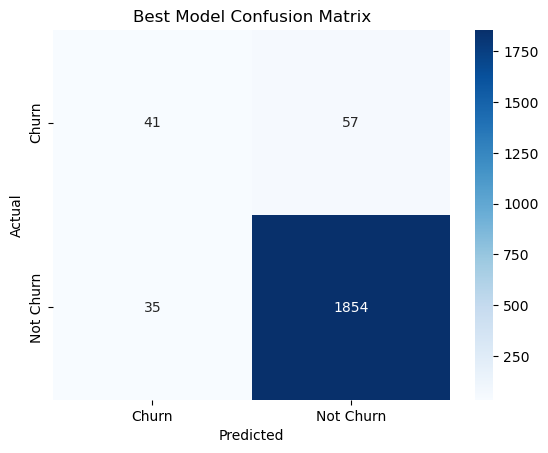

In [31]:
best_predictions = best_model.predict(X_test)

print(classification_report(
    y_test,
    best_predictions,
    target_names=label_encoder.classes_
))

cm = confusion_matrix(y_test, best_predictions)

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Best Model Confusion Matrix")
plt.show()

In [32]:
joblib.dump(best_model, "best_churn_model.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

print("Best model saved successfully!")

Best model saved successfully!


In [33]:
import joblib

raw_columns = [
    col for col in df.columns
    if col not in ["Churn", "Customer_ID"]
]

metadata = {
    "raw_columns": raw_columns,
    "usage_threshold": float(usage_threshold),
    "model_features": X.columns.tolist()
}

joblib.dump(metadata, "api_metadata.pkl")

print("Model metadata saved successfully.")
print("Required input columns:", raw_columns)

Model metadata saved successfully.
Required input columns: ['Gender', 'Senior_Citizen', 'Tenure_Months', 'Contract_Type', 'Internet_Service', 'Payment_Method', 'Monthly_Charges_INR', 'Total_Charges_INR', 'Tech_Support', 'Online_Security', 'Support_Tickets_6M', 'Avg_Data_Usage_GB']


In [34]:
%%writefile api.py

import pandas as pd
import numpy as np
import joblib

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
from typing import Dict, Any

app = FastAPI(
    title="Customer Churn Prediction API",
    description="API for predicting customer churn",
    version="1.0"
)

# Load saved model and metadata
model = joblib.load("best_churn_model.pkl")
label_encoder = joblib.load("label_encoder.pkl")
metadata = joblib.load("api_metadata.pkl")

RAW_COLUMNS = metadata["raw_columns"]
USAGE_THRESHOLD = metadata["usage_threshold"]
MODEL_FEATURES = metadata["model_features"]


class CustomerData(BaseModel):
    customer: Dict[str, Any]


def create_features(data):
    df = pd.DataFrame([data])

    # Convert numeric columns
    numeric_columns = [
        "Tenure_Months",
        "Monthly_Charges_INR",
        "Total_Charges_INR",
        "Support_Tickets_6M",
        "Avg_Data_Usage_GB"
    ]

    for col in numeric_columns:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    # Handle invalid values consistently with training
    if "Tenure_Months" in df.columns:
        df.loc[
            (df["Tenure_Months"] < 0) |
            (df["Tenure_Months"] > 72),
            "Tenure_Months"
        ] = np.nan

    for col in [
        "Monthly_Charges_INR",
        "Total_Charges_INR",
        "Support_Tickets_6M",
        "Avg_Data_Usage_GB"
    ]:
        if col in df.columns:
            df.loc[df[col] < 0, col] = np.nan

    # Tenure category
    df["Tenure_Category"] = pd.cut(
        df["Tenure_Months"],
        bins=[-1, 12, 24, 48, 72],
        labels=["New", "Short-term", "Medium-term", "Long-term"]
    )

    # Average monthly spending
    df["Average_Monthly_Spending"] = np.where(
        df["Tenure_Months"] > 0,
        df["Total_Charges_INR"] / df["Tenure_Months"],
        df["Monthly_Charges_INR"]
    )

    # Service indicators
    internet = (
        df["Internet_Service"].astype(str).str.strip().str.lower()
    )
    df["Has_Internet_Service"] = internet.isin(
        ["yes", "fiber optic", "dsl", "true", "1"]
    ).astype(int)

    tech = df["Tech_Support"].astype(str).str.strip().str.lower()
    df["Has_Tech_Support"] = tech.isin(
        ["yes", "true", "1"]
    ).astype(int)

    security = (
        df["Online_Security"].astype(str).str.strip().str.lower()
    )
    df["Has_Online_Security"] = security.isin(
        ["yes", "true", "1"]
    ).astype(int)

    # Ticket intensity
    df["Ticket_Intensity"] = np.where(
        df["Tenure_Months"] > 0,
        df["Support_Tickets_6M"] / df["Tenure_Months"],
        df["Support_Tickets_6M"]
    )

    # High data usage
    df["High_Data_Usage"] = (
        df["Avg_Data_Usage_GB"] > USAGE_THRESHOLD
    ).astype(int)

    # Match training feature order
    return df.reindex(columns=MODEL_FEATURES)


@app.get("/health")
def health():
    return {
        "status": "healthy",
        "model_loaded": model is not None
    }


@app.post("/predict")
def predict(customer_data: CustomerData):

    try:
        customer = customer_data.customer

        missing_columns = [
            col for col in RAW_COLUMNS
            if col not in customer
        ]

        if missing_columns:
            raise HTTPException(
                status_code=400,
                detail=f"Missing fields: {missing_columns}"
            )

        features = create_features(customer)

        prediction = model.predict(features)[0]
        churn_status = label_encoder.inverse_transform(
            [int(prediction)]
        )[0]

        return {
            "prediction": str(churn_status),
            "message": "Customer is likely to churn"
            if str(churn_status).lower() == "churn"
            else "Customer is likely to stay"
        }

    except HTTPException:
        raise

    except Exception as e:
        raise HTTPException(status_code=500, detail=str(e))

Writing api.py


In [35]:
%pip install fastapi uvicorn pydantic

Note: you may need to restart the kernel to use updated packages.


In [36]:
from fastapi.testclient import TestClient
from api import app

client = TestClient(app)

response = client.get("/health")

print("Status code:", response.status_code)
print("Response:", response.json())

Status code: 200
Response: {'status': 'healthy', 'model_loaded': True}


In [37]:
sample_customer = df.drop(
    columns=["Churn", "Customer_ID"],
    errors="ignore"
).iloc[0].to_dict()

response = client.post(
    "/predict",
    json={"customer": sample_customer}
)

print("Status code:", response.status_code)
print("Prediction:", response.json())

Status code: 200
Prediction: {'prediction': 'Churn', 'message': 'Customer is likely to churn'}
